# **Session 12: Decorators and Namespaces**

[Watch Here](https://www.youtube.com/live/aMARZGTbULc?si=ZU8neI5Sm4KUak0c)

## **Namespaces**

A namespace is a space that holds names(identifiers).Programmatically speaking, namespaces are dictionary of identifiers(keys) and their objects(values)

**There are 4 types of namespaces**:
- Builtin Namespace
- Global Namespace
- Enclosing Namespace
- Local Namespace

### **Scope and LEGB Rule**

**Scope**

- A scope is a textual region of a Python program where a namespace is directly accessible.


**LEGB Rule**

- The interpreter searches for a name from the inside out, looking in the local, enclosing, global, and finally the built-in scope.

- If the interpreter doesn’t find the name in any of these locations, then Python raises a NameError exception.

**Here, `a = 2` and `b = 3` belong to the global namespace and the box here is scope accessible throughout the global scope.**

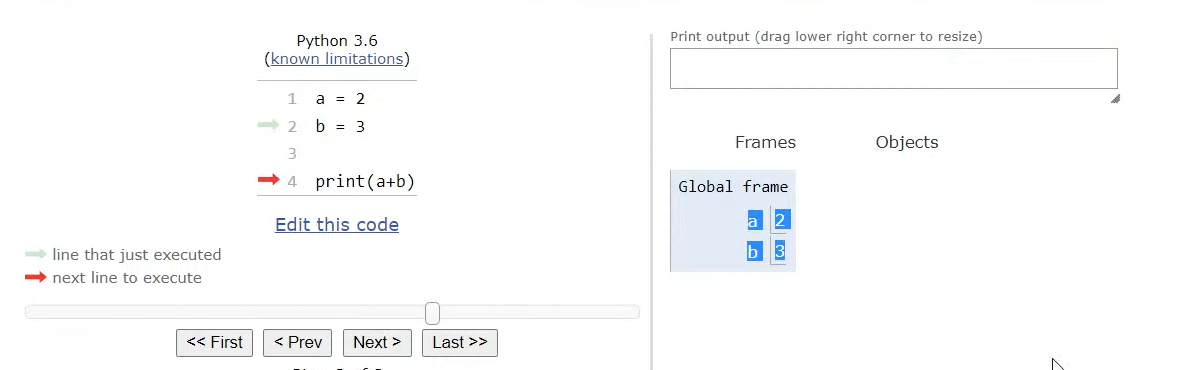

#### **Local Scope and Global Scope**

In [ ]:
# local and global

# global var
a = 2

def temp():
  # local var
  b = 3
  print(b)

temp()
print(a)

3
2


In [ ]:
# local and global -> same name

# global var
a = 2

def temp():
  # local var
  a = 3
  print(a)

temp()
print(a)

3
2


In [ ]:
# local and global -> local does not have but global has

# global var
a = 2

def temp():
  # local var
  print(a)

temp()
print(a)

2
2


In [ ]:
# local and global -> editing global -> Cannot change directly

# global var
a = 2

def temp():
  # local var
  a += 1
  print(a)

temp()
print(a)

UnboundLocalError: cannot access local variable 'a' where it is not associated with a value

In [ ]:
# local and global -> editing global -> changes using global keyword -> Avoid it

# global var
a = 2

def temp():
  # local var
  global a
  a += 1
  print(a)

temp()
print(a)

3
3


In [ ]:
# local and global -> global created inside local -> Not a good practise

def temp():
  # local var
  global a
  a = 1
  print(a)

temp()
print(a)

1
1


In [ ]:
# local and global -> function parameter inside local

def temp(z):
  # local var
  print(z)

a = 5

temp(5)
print(a)

5
5


In [ ]:
def temp(z):
  # local var
  print(z)

a = 5

temp(5)
print(a)
print(z)

5
5


NameError: name 'z' is not defined

#### **Built-in Scope**

In [ ]:
# built-in scope -> print()

print('hello')

hello


In [ ]:
# built-in scope -> type()

print(type('hello'))

<class 'str'>


In [ ]:
# How to see all the built-ins

import builtins
print(dir(builtins))

['ArithmeticError', 'AssertionError', 'AttributeError', 'BaseException', 'BaseExceptionGroup', 'BlockingIOError', 'BrokenPipeError', 'BufferError', 'BytesWarning', 'ChildProcessError', 'ConnectionAbortedError', 'ConnectionError', 'ConnectionRefusedError', 'ConnectionResetError', 'DeprecationWarning', 'EOFError', 'Ellipsis', 'EncodingWarning', 'EnvironmentError', 'Exception', 'ExceptionGroup', 'False', 'FileExistsError', 'FileNotFoundError', 'FloatingPointError', 'FutureWarning', 'GeneratorExit', 'IOError', 'ImportError', 'ImportWarning', 'IndentationError', 'IndexError', 'InterruptedError', 'IsADirectoryError', 'KeyError', 'KeyboardInterrupt', 'LookupError', 'MemoryError', 'ModuleNotFoundError', 'NameError', 'None', 'NotADirectoryError', 'NotImplemented', 'NotImplementedError', 'OSError', 'OverflowError', 'PendingDeprecationWarning', 'PermissionError', 'ProcessLookupError', 'RecursionError', 'ReferenceError', 'ResourceWarning', 'RuntimeError', 'RuntimeWarning', 'StopAsyncIteration', 'S

In [ ]:
# Renaming built-ins

L = [1,2,3]
print(max(L))
def max():
  print('hello')

print(max(L))

3


TypeError: max() takes 0 positional arguments but 1 was given

In [ ]:
# Renaming built-ins

L = [1,2,3]
def max():
  print('hello')

print(max())

hello
None


In [ ]:
# Renaming built-ins

L = [1,2,3]
print(max(L))
def max():
  print('hello')

print(max(L))

TypeError: max() takes 0 positional arguments but 1 was given

#### **Enclosing Scope**

In [ ]:
# Enclosing scope -> Inside nested function

def outer():
  def inner():
    print('inner function')
  inner()
  print('outer function')

outer()
print('main program')

inner function
outer function
main program


In [ ]:
# Enclosing scope

def outer():
  a = 3
  def inner():
    a = 4
    print(a)
  inner()
  print('outer function')

a = 1

outer()
print('main program')

4
outer function
main program


In [ ]:
# Enclosing scope

def outer():
  a = 3
  def inner():
    print(a)
  inner()
  print('outer function')

a = 1

outer()
print('main program')

3
outer function
main program


In [ ]:
# Enclosing scope

def outer():
  def inner():
    print(a)
  inner()
  print('outer function')

a = 1

outer()
print('main program')

1
outer function
main program


In [ ]:
# Enclosing scope -> NameError: name 'a' is not defined

def outer():
  def inner():
    print(a)
  inner()
  print('outer function')

outer()
print('main program')

1
outer function
main program


In [ ]:
# nonlocal keyword -> You can changes in enclosing scope -> Avoid it

def outer():
  a = 1
  def inner():
    nonlocal a
    a += 1
    print('inner',a)
  inner()
  print('outer',a)

outer()
print('main program')

inner 2
outer 2
main program


## **Decorators**

A decorator in python is a function that receives another function as input and adds some functionality(decoration) to and it and returns it.

This can happen only because python functions are **1st class citizens**.

**There are 2 types of decorators available in python**

**1. `Built in decorators`** like `@staticmethod`, `@classmethod`, `@abstractmethod` and `@property` etc

**2. `User defined decorators`** that we programmers can create according to our needs.

## **Closure**

A closure is a function object that remembers variables from its enclosing scope even after the outer function has completed execution.


In [ ]:
# Python are 1st class function

# Decorator
def modify(func,num):
  return func(num)

# Input
def square(num):
  return num**2

modify(square,2)

4

In [ ]:
# Simple example

def my_decorator(func):
  def wrapper():
    print('***********************')
    func()
    print('***********************')
  return wrapper

def hello():
  print('hello')

def display():
  print('hello nitish')

a = my_decorator(hello)
a()

b = my_decorator(display)
b()

***********************
hello
***********************
***********************
hello nitish
***********************


In [ ]:
# Better syntax -> @decorator_name

def my_decorator(func):
  def wrapper():
    print('***********************')
    func()
    print('***********************')
  return wrapper

@my_decorator
def hello():
  print('hello')

hello()

***********************
hello
***********************


In [ ]:
# Anything meaningful?

import time

def timer(func):
  def wrapper(*args):
    start = time.time()
    func(*args)
    print('Time taken by',func.__name__,time.time() - start,'secs')
  return wrapper

@timer
def hello():
  print('Hello World')
  time.sleep(2)

@timer
def display():
  print('Displaying Something')
  time.sleep(2)

hello()
display()

Hello World
Time taken by hello 2.0002377033233643 secs
Displaying Something
Time taken by display 2.0001301765441895 secs


In [ ]:
# A big problem

import time

def timer(func):
  def wrapper():
    start = time.time()
    func()
    print('Time taken by',func.__name__,time.time() - start,'secs')
  return wrapper

@timer
def hello():
  print('Hello World')
  time.sleep(2)

@timer
def square(num):
  time.sleep(1)
  print(num**2)

square(2)

TypeError: timer.<locals>.wrapper() takes 0 positional arguments but 1 was given

In [ ]:
# A big problem -> Solve by *args

import time

def timer(func):
  def wrapper(*args):
    start = time.time()
    func(*args)
    print('Time taken by',func.__name__,time.time() - start,'secs')
  return wrapper

@timer
def hello():
  print('Hello World')
  time.sleep(2)

@timer
def square(num):
  time.sleep(1)
  print(num**2)

@timer
def power(a,b):
  print(a**b)

hello()
square(2)
power(2,3)

Hello World
Time taken by hello 2.0003502368927 secs
4
Time taken by square 1.000356674194336 secs
8
Time taken by power 1.5497207641601562e-05 secs


In [ ]:
def square(num):
  print(num**2)

In [ ]:
square(2)

4


In [ ]:
square('hehe')

TypeError: unsupported operand type(s) for ** or pow(): 'str' and 'int'

In [ ]:
# One last example -> decorators with arguments

def sanity_check(data_type):
  def outer_wrapper(func):
    def inner_wrapper(*args):
      if type(*args) == data_type:
        func(*args)
      else:
        raise TypeError('Ye datatype nai chalega')
    return inner_wrapper
  return outer_wrapper

@sanity_check(int)
def square(num):
  print(num**2)

@sanity_check(str)
def greet(name):
  print('Hello',name)

In [ ]:
square(2)

4


In [ ]:
square(4.5)

TypeError: Ye datatype nai chalega

In [ ]:
square('hehe')

TypeError: Ye datatype nai chalega

In [ ]:
greet('Himanshu')

Hello Himanshu


In [ ]:
greet(2)

TypeError: Ye datatype nai chalega

In [ ]:
greet('Nitish')

Hello Nitish


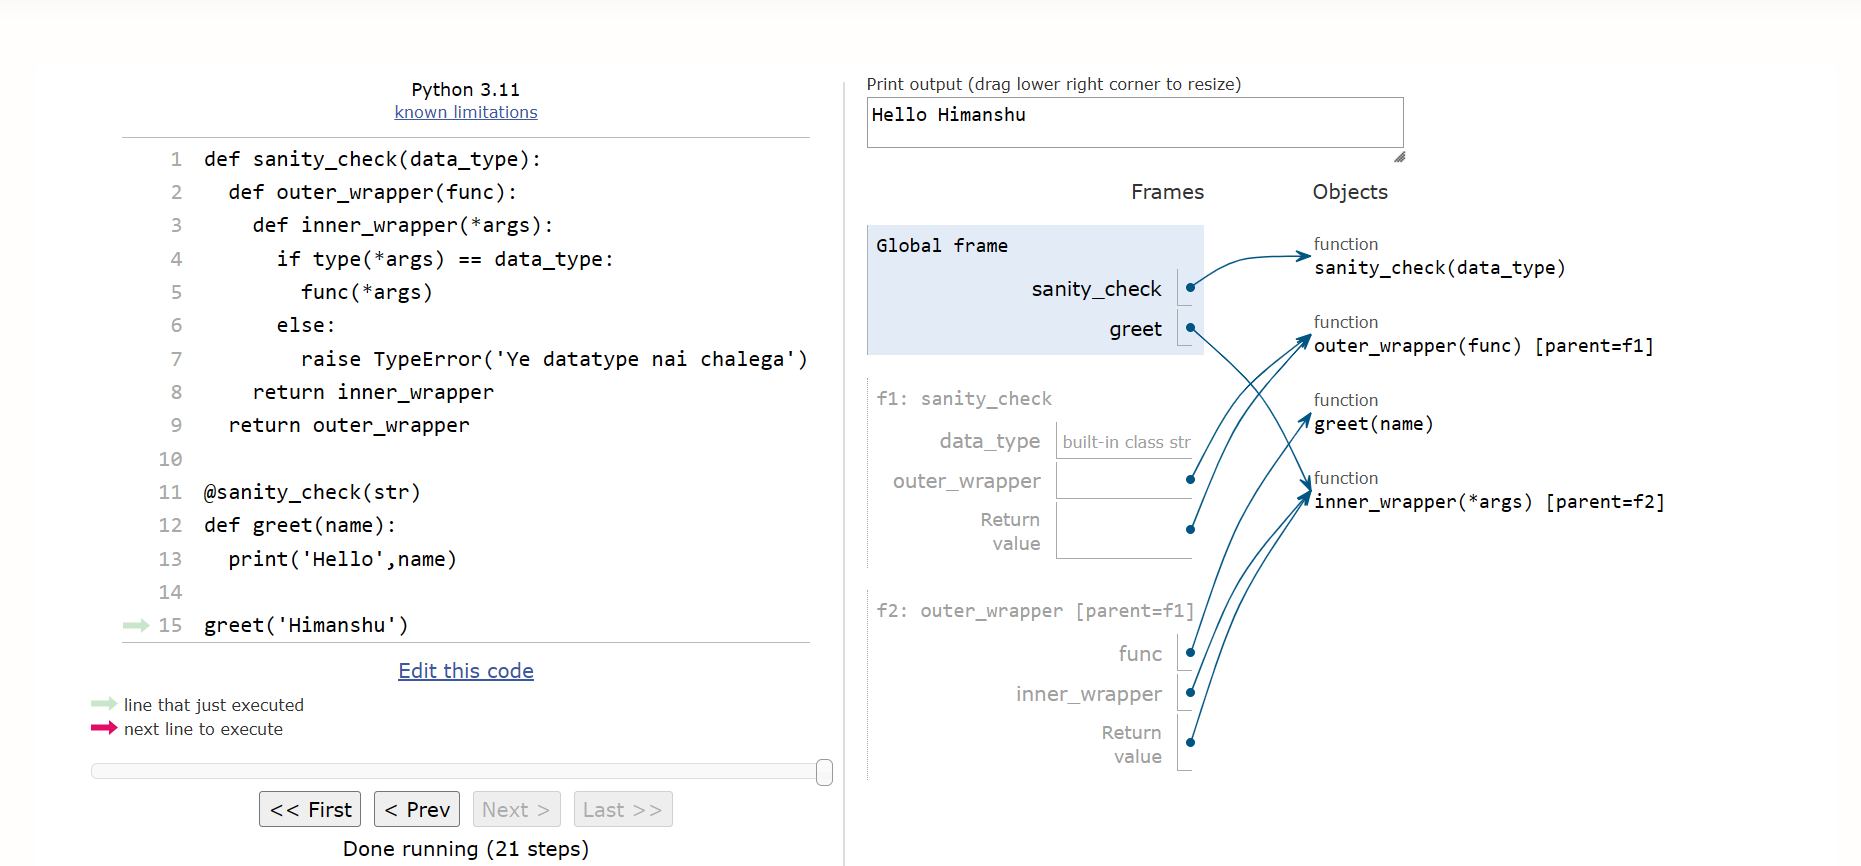